In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path.cwd() / 'data'

In [2]:
df_client = pd.read_csv(DATA / 'client.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])

In [3]:
df_account = pd.read_csv(DATA / 'account.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])

In [4]:
df_client.head(5)

,client_id,birth_number,district_id
0,1,706213,18
1,2,450204,1
2,3,406009,1
3,4,561201,5
4,5,605703,5


In [5]:
df_account.head()

,account_id,district_id,frequency,date
0,576,55,POPLATEK MESICNE,930101
1,3818,74,POPLATEK MESICNE,930101
2,704,55,POPLATEK MESICNE,930101
3,2378,16,POPLATEK MESICNE,930101
4,2632,24,POPLATEK MESICNE,930102


In [6]:
df_client.dtypes

client_id       int64
birth_number    int64
district_id     int64
dtype: object

In [7]:
df_account.dtypes

account_id      int64
district_id     int64
frequency      object
date            int64
dtype: object

In [8]:
df_client["client_id"] = df_client["client_id"].astype('object')

In [9]:
df_client.dtypes

client_id       object
birth_number     int64
district_id      int64
dtype: object

In [10]:
df_client.describe(include = 'all')

,client_id,birth_number,district_id
count,5369.0,5369.000000,5369.000000
unique,5369.0,NaN,NaN
top,1.0,NaN,NaN
freq,1.0,NaN,NaN
mean,NaN,535114.970013,37.310114
std,NaN,172895.618429,25.043690
min,NaN,110820.000000,1.000000
25%,NaN,406009.000000,14.000000
50%,NaN,540829.000000,38.000000
75%,NaN,681013.000000,60.000000


In [11]:
df_account.describe()

,account_id,district_id,date
count,4500.000000,4500.000000,4500.000000
mean,2786.067556,37.310444,951654.608667
std,2313.811984,25.177217,14842.188377
min,1.000000,1.000000,930101.000000
25%,1182.750000,13.000000,931227.000000
50%,2368.000000,38.000000,960102.000000
75%,3552.250000,60.000000,961101.000000
max,11382.000000,77.000000,971229.000000


<Axes: >

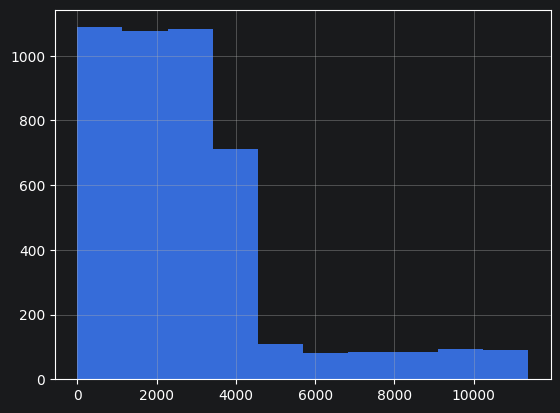

In [12]:
df_account['account_id'].hist()

No importa que paresca número se debe convertir en object
La columna account_id es un valor unico o compartido por algunas instancias

In [13]:
df_account["account_id"] = df_account["account_id"].astype('object')

In [14]:
df_account = df_account.astype({'account_id':'object', 'district_id':'object'})

In [15]:
df_account.dtypes

account_id     object
district_id    object
frequency      object
date            int64
dtype: object

In [16]:
df_client.describe(include = 'all')

,client_id,birth_number,district_id
count,5369.0,5369.000000,5369.000000
unique,5369.0,NaN,NaN
top,1.0,NaN,NaN
freq,1.0,NaN,NaN
mean,NaN,535114.970013,37.310114
std,NaN,172895.618429,25.043690
min,NaN,110820.000000,1.000000
25%,NaN,406009.000000,14.000000
50%,NaN,540829.000000,38.000000
75%,NaN,681013.000000,60.000000


In [17]:
df_account.describe(include = 'all')

,account_id,district_id,frequency,date
count,4500.0,4500.0,4500,4500.000000
unique,4500.0,77.0,3,NaN
top,576.0,1.0,POPLATEK MESICNE,NaN
freq,1.0,554.0,4167,NaN
mean,NaN,NaN,NaN,951654.608667
std,NaN,NaN,NaN,14842.188377
min,NaN,NaN,NaN,930101.000000
25%,NaN,NaN,NaN,931227.000000
50%,NaN,NaN,NaN,960102.000000
75%,NaN,NaN,NaN,961101.000000


In [18]:
df_account.columns

Index(['account_id', 'district_id', 'frequency', 'date'], dtype='object')

In [19]:
df_account.sample(4).head(4).T

,1776,3982,1114,1472
account_id,4423,3202,2733,3975
district_id,39,8,76,20
frequency,POPLATEK MESICNE,POPLATEK MESICNE,POPLATEK MESICNE,POPLATEK MESICNE
date,950426,970604,931222,941002


In [20]:
df_account.head()

,account_id,district_id,frequency,date
0,576,55,POPLATEK MESICNE,930101
1,3818,74,POPLATEK MESICNE,930101
2,704,55,POPLATEK MESICNE,930101
3,2378,16,POPLATEK MESICNE,930101
4,2632,24,POPLATEK MESICNE,930102


In [21]:
### Analisis bivariado respecto de la variable objetivo

In [22]:
df_disp = pd.read_csv(DATA / 'disp.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])
df_loan = pd.read_csv(DATA / 'loan.asc', sep=';', na_values=[' ', '', 'NA', 'NULL', 'NaN'])

df_account_loan = pd.merge(df_account, df_loan, on='account_id', how='inner')

df_account_loan.groupby(['status']).agg({
    'amount':'mean', 
    'duration':'mean', 
    'payments':'mean'
}).sort_values(['status'], ascending = True)

,amount,duration,payments
status,,,
A,91641.458128,22.226601,4264.137931
B,140720.903226,25.548387,5396.258065
C,171410.352357,43.444169,3938.535980
D,249284.533333,46.133333,5286.644444


In [23]:
df_disp_owner = df_disp[df_disp['type'] == 'OWNER']
df_berka = pd.merge(df_client, df_disp_owner, on='client_id')
df_berka = pd.merge(df_berka, df_account, on='account_id', suffixes=('_client', '_account'))
df_berka = pd.merge(df_berka, df_loan[['account_id', 'amount', 'duration', 'payments', 'status']], on='account_id', how='left')
df_berka['target'] = df_berka['status'].map({'A': 1, 'C': 1, 'B': 0, 'D': 0})

df_berka.head(1).T

,0
client_id,1
birth_number,706213
district_id_client,18
disp_id,1
account_id,1
type,OWNER
district_id_account,18
frequency,POPLATEK MESICNE
date,950324
amount,NaN


In [24]:
df_berka.groupby(['target']).agg({'amount':'mean', 'payments':'mean'}).sort_values(['target'], ascending = True)

,amount,payments
target,,
0.0,205002.000000,5331.355263
1.0,144689.089109,4047.607261


## Analisis bivariado entre variables categóricas

In [25]:
df_berka.groupby(['frequency','target'], dropna=False).agg({'amount':'mean'})

amount
frequency          target               
POPLATEK MESICNE   0.0     210890.440678
                   1.0     139723.488000
                   NaN               NaN
POPLATEK PO OBRATU 0.0     135040.000000
                   1.0     171462.461538
                   NaN               NaN
POPLATEK TYDNE     0.0     211579.636364
                   1.0     167022.750000
                   NaN               NaN

In [26]:
df_berka.groupby(['frequency','status'], dropna=False).agg({'amount':'mean'})

amount
frequency          status               
POPLATEK MESICNE   A        87465.428571
                   B       132923.454545
                   C       166167.325301
                   D       257249.189189
                   NaN               NaN
POPLATEK PO OBRATU A       116614.500000
                   B        95260.000000
                   C       195839.333333
                   D       174820.000000
                   NaN               NaN
POPLATEK TYDNE     A       110226.222222
                   B       192042.000000
                   C       195956.830189
                   D       235024.800000
                   NaN               NaN

In [27]:
df_berka.groupby(['type','target'], dropna=False).agg({'amount':'mean'})

amount
type  target               
OWNER 0.0     205002.000000
      1.0     144689.089109
      NaN               NaN

## Análisis bivariado de cinco variables frente a `target` (Figura 2 y Tabla 4 del informe)

Variables comparadas contra la variable respuesta: `amount`, `payments`, `duration` (condiciones del crédito), `edad` (derivada de `birth_number`, al 31-12-1998) y `frequency` (característica de la cuenta).

* Cuantitativas: comparación de medias y distribuciones por clase con la prueba **Mann-Whitney** (no asume normalidad).
* `frequency`: prueba **χ² de independencia**.
* Se trabaja con los 682 titulares que tienen préstamo (los únicos con `target` definido).

In [28]:
# Preparación de las variables para el análisis bivariado
from pathlib import Path
from scipy import stats

sns.set_theme(style='whitegrid')
FIG = Path('figuras_aed')
FIG.mkdir(exist_ok=True)
FECHA_REF = pd.Timestamp('1998-12-31')      # último día con datos en la base Berka

# Población con variable respuesta definida (titulares con préstamo)
prest = df_berka.dropna(subset=['target']).copy()
prest['target'] = prest['target'].astype(int)

# edad al 31-12-1998 desde birth_number (AAMMDD; en las mujeres el mes lleva +50)
bn = prest['birth_number'].astype(str).str.zfill(6)
mes_codigo = bn.str[2:4].astype(int)
mes_real = mes_codigo.where(mes_codigo <= 50, mes_codigo - 50)
fecha_nac = pd.to_datetime(pd.DataFrame({'year': 1900 + bn.str[0:2].astype(int),
                                         'month': mes_real,
                                         'day': bn.str[4:6].astype(int)}))
prest['edad'] = ((FECHA_REF - fecha_nac).dt.days / 365.25).round(1)

# Etiquetas legibles
prest['clase'] = prest['target'].map({1: 'Bueno (1)', 0: 'Malo (0)'})
prest['frecuencia'] = prest['frequency'].map({'POPLATEK MESICNE': 'mensual',
                                              'POPLATEK TYDNE': 'semanal',
                                              'POPLATEK PO OBRATU': 'por transacción'})
print(len(prest), 'titulares con préstamo')
prest[['amount', 'payments', 'duration', 'edad']].describe().round(2)

682 titulares con préstamo


,amount,payments,duration,edad
count,682.00,682.00,682.00,682.00
mean,151410.18,4190.66,36.49,40.40
std,113372.41,2215.83,17.08,12.67
min,4980.00,304.00,12.00,18.10
25%,66732.00,2477.00,24.00,29.82
50%,116928.00,3934.00,36.00,40.40
75%,210654.00,5813.50,48.00,51.10
max,590820.00,9910.00,60.00,63.90


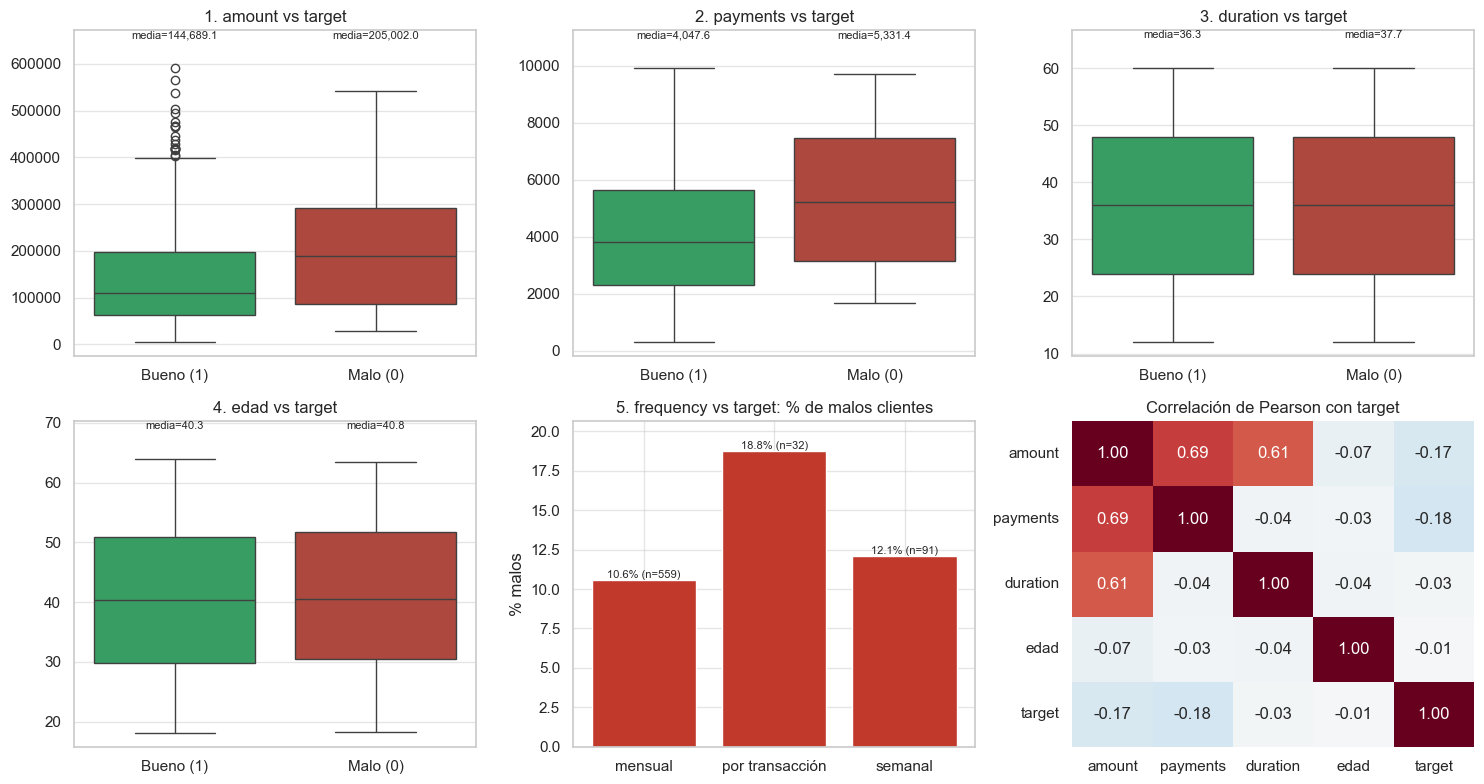

In [29]:
# Figura 2. Cinco variables vs target + matriz de correlación
orden = ['Bueno (1)', 'Malo (0)']
paleta = {'Bueno (1)': '#27ae60', 'Malo (0)': '#c0392b'}

fig, ax = plt.subplots(2, 3, figsize=(15, 8))

# 1-4: boxplots de las cuantitativas por clase, con la media de cada clase arriba
for i, (a, var) in enumerate(zip(ax.flat[:4], ['amount', 'payments', 'duration', 'edad']), start=1):
    sns.boxplot(data=prest, x='clase', y=var, order=orden, hue='clase', palette=paleta, legend=False, ax=a)
    a.set_title(f'{i}. {var} vs target')
    a.set_xlabel('')
    a.set_ylabel('')
    ymin, ymax = a.get_ylim()
    a.set_ylim(ymin, ymax + (ymax - ymin) * 0.08)          # espacio para el texto de la media
    for j, cl in enumerate(orden):
        media = prest.loc[prest['clase'] == cl, var].mean()
        a.text(j, a.get_ylim()[1], f'media={media:,.1f}', ha='center', va='top', fontsize=8)

# 5: % de malos clientes según frecuencia de emisión
mal = prest.groupby('frecuencia')['target'].agg(pct_malos=lambda s: (s == 0).mean() * 100, n='size')
a = ax[1, 1]
a.bar(mal.index, mal['pct_malos'], color='#c0392b')
for k, (p, n) in enumerate(zip(mal['pct_malos'], mal['n'])):
    a.text(k, p, f'{p:.1f}% (n={n})', ha='center', va='bottom', fontsize=8)
a.set_title('5. frequency vs target: % de malos clientes')
a.set_ylabel('% malos')
a.set_ylim(0, mal['pct_malos'].max() * 1.1)

# 6: correlación de Pearson
corr = prest[['amount', 'payments', 'duration', 'edad', 'target']].corr(method='pearson')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, cbar=False, ax=ax[1, 2])
ax[1, 2].set_title('Correlación de Pearson con target')

plt.tight_layout()
plt.savefig(FIG / 'fig2_bivariado_target.png', dpi=130, bbox_inches='tight')
plt.show()

In [30]:
# Tabla 4. Comparación entre buenos (Y = 1) y malos clientes (Y = 0) + pruebas de hipótesis
filas = []
for var in ['amount', 'payments', 'duration', 'edad']:
    b = prest.loc[prest['target'] == 1, var]
    m = prest.loc[prest['target'] == 0, var]
    _, p = stats.mannwhitneyu(b, m, alternative='two-sided')
    filas.append({'Variable': var, 'Media buenos': round(b.mean(), 1), 'Media malos': round(m.mean(), 1),
                  'Diferencia (%)': round((m.mean() / b.mean() - 1) * 100, 1),
                  'Prueba': 'Mann-Whitney', 'p-valor': p})

# frequency es categórica: chi-cuadrado de independencia sobre la tabla de contingencia
ct = pd.crosstab(prest['frecuencia'], prest['target'])
_, p_chi, _, _ = stats.chi2_contingency(ct)
filas.append({'Variable': 'frequency', 'Media buenos': np.nan, 'Media malos': np.nan,
              'Diferencia (%)': np.nan, 'Prueba': 'Chi-cuadrado', 'p-valor': p_chi})

tabla4 = pd.DataFrame(filas)
tabla4['p-valor'] = tabla4['p-valor'].map(lambda p: '< 0.001' if p < 0.001 else f'{p:.2f}')
tabla4['Significativa (α = 0.05)'] = tabla4['p-valor'].map(
    lambda s: 'Sí' if s == '< 0.001' or float(s) < 0.05 else 'No')
display(tabla4)

,Variable,Media buenos,Media malos,Diferencia (%),Prueba,p-valor,Significativa (α = 0.05)
0,amount,144689.1,205002.0,41.7,Mann-Whitney,< 0.001,Sí
1,payments,4047.6,5331.4,31.7,Mann-Whitney,< 0.001,Sí
2,duration,36.3,37.7,3.9,Mann-Whitney,0.50,No
3,edad,40.3,40.8,1.1,Mann-Whitney,0.77,No
4,frequency,NaN,NaN,NaN,Chi-cuadrado,0.34,No


In [31]:
# Hipótesis 3: ¿los plazos largos (>= 48 meses) tienen más mora que los cortos? (χ² de independencia)
prest['plazo'] = np.where(prest['duration'] >= 48, '>= 48 meses', '< 48 meses')
ct3 = pd.crosstab(prest['plazo'], prest['target'])
chi2, p3, _, _ = stats.chi2_contingency(ct3)

resumen = pd.DataFrame({'n': ct3.sum(axis=1), '% de malos': (ct3[0] / ct3.sum(axis=1) * 100).round(1)})
display(resumen)
print(f'χ² = {chi2:.2f} | p = {p3:.2f}  ->  la diferencia no es estadísticamente significativa (H3 no se confirma)')

,n,% de malos
plazo,,
< 48 meses,399,10.8
>= 48 meses,283,11.7


χ² = 0.06 | p = 0.81  ->  la diferencia no es estadísticamente significativa (H3 no se confirma)
